# Phase 5b — Shared Split & Significance Tests

Revision steps 6 and 9 from `NEXT_STEPS.md` (PeerJ resubmission).

**Step 6: one shared split.** Phase 5 compared strategies on different footing:
* audio-only retrieved from a 3,232-track catalog, while lyrics/fusion retrieved from 2,075 tracks;
* queries came from the *audio* test split, but the MERGE audio and lyrics splits do not agree on
  multimodal tracks (some audio-test tracks sit in the lyrics *train* split).

Here every strategy uses **the same catalog** (the 2,075 multimodal tracks) and **the same queries**:
tracks assigned to the same subset in *both* the audio and the lyrics split. Late-fusion α is tuned on
the shared validation set only. The full audio catalog, including the 1,157 tracks without lyrics, is
reported as a separate audio-only analysis.

**Step 9: statistics.** All metrics are kept per query, so strategies can be compared with paired tests:
paired bootstrap 95% CIs on the mean difference, and Wilcoxon signed-rank tests with Holm correction.

Retrieval is exact cosine top-k (dense matrix product), equivalent to the `IndexFlatIP` indexes from Phase 4.
Cell 2 checks that by reproducing the Phase 5 headline numbers.

Like Phase 5, this notebook reads AV values and quadrants for evaluation only. It never reads `moods`, `genres` or `themes`.

In [1]:
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import wilcoxon

warnings.filterwarnings('ignore')

ROOT = os.environ.get('MUSIC_RESEARCH_ROOT', os.path.abspath('.'))
OUT_DIR = os.path.join(ROOT, 'outputs')

K_LIST = [5, 10, 20]
ALPHAS = [0.2, 0.4, 0.5, 0.6, 0.8]
N_BOOT = 10_000
SEED   = 42
SCHEMES = {'tvt_70_15_15': '70/15/15', 'tvt_40_30_30': '40/30/30'}

# ── Features and labels ───────────────────────────────────────────────────────
audio_df  = pd.read_parquet(os.path.join(OUT_DIR, 'audio_features.parquet'))
lyrics_df = pd.read_parquet(os.path.join(OUT_DIR, 'lyrics_features.parquet'))
merged    = pd.read_parquet(os.path.join(OUT_DIR, 'merged_dataset.parquet'))

def l2n(X):
    X = np.asarray(X, dtype=np.float64)
    return X / np.linalg.norm(X, axis=1, keepdims=True)

audio_sids_all = audio_df['song_id'].tolist()
audio_row      = {s: i for i, s in enumerate(audio_sids_all)}
clap_all       = l2n(np.vstack(audio_df['audio_clap'].values))           # (3232, 512)
clap_raw_all   = np.vstack(audio_df['audio_clap_raw'].values)

# Shared catalog = multimodal tracks, in lyrics_features order
cat_sids = lyrics_df['song_id'].tolist()
cat_pos  = {s: i for i, s in enumerate(cat_sids)}
a_idx    = [audio_row[s] for s in cat_sids]
X_audio  = clap_all[a_idx]                                               # (2075, 512)
X_lyrics = l2n(np.vstack(lyrics_df['lyrics_sbert'].values))              # (2075, 768)
sbert_raw = np.vstack(lyrics_df['lyrics_sbert_raw'].values)
X_early  = l2n(np.hstack([clap_raw_all[a_idx], sbert_raw]))              # same as Phase 4 early_fusion index

lab = merged.set_index('song_id')
quad_all = lab['quadrant'].to_dict()
av_all   = {s: np.array([r.arousal, r.valence]) for s, r in lab[['arousal', 'valence']].iterrows()}

# Lyrics split files use lyrics filenames (MT… or L…-…); map them to song_id
mm = merged[merged['is_multimodal']]
lyr_stem_to_sid = {os.path.splitext(os.path.basename(p))[0]: s
                   for s, p in zip(mm['song_id'], mm['lyrics_path'])}

def read_split(modality, scheme, subset):
    folder = 'MERGE_Audio_Balanced' if modality == 'audio' else 'MERGE_Lyrics_Balanced'
    path = os.path.join(ROOT, folder, 'tvt_dataframes', scheme, f'{scheme}_{subset}_{modality}_balanced.csv')
    ids = pd.read_csv(path)['Song']
    if modality == 'lyrics':
        ids = ids.map(lyr_stem_to_sid).dropna()
    return set(ids)

splits = {(m, sc, sub): read_split(m, sc, sub)
          for m in ['audio', 'lyrics'] for sc in SCHEMES for sub in ['train', 'validate', 'test']}

cat_set = set(cat_sids)
rows = []
for sc, lbl in SCHEMES.items():
    for sub in ['train', 'validate', 'test']:
        A = splits[('audio', sc, sub)] & cat_set
        L = splits[('lyrics', sc, sub)]
        rows.append({'scheme': lbl, 'subset': sub, 'audio_split ∩ multimodal': len(A),
                     'lyrics_split': len(L), 'shared (both)': len(A & L)})
split_table = pd.DataFrame(rows)
print(split_table.to_string(index=False))

# Cross-modality leakage: multimodal audio-test tracks that sit in the lyrics train split
for sc, lbl in SCHEMES.items():
    leak = splits[('audio', sc, 'test')] & splits[('lyrics', sc, 'train')]
    print(f'{lbl}: {len(leak)} multimodal tracks are in the audio TEST split but the lyrics TRAIN split')

  scheme   subset  audio_split ∩ multimodal  lyrics_split  shared (both)
70/15/15    train                      1278          1372           1187
70/15/15 validate                       400           352            305
70/15/15     test                       397           351            302
40/30/30    train                       586           700            475
40/30/30 validate                       741           693            616
40/30/30     test                       748           682            617
70/15/15: 92 multimodal tracks are in the audio TEST split but the lyrics TRAIN split
40/30/30: 111 multimodal tracks are in the audio TEST split but the lyrics TRAIN split


## 1. Retrieval and per-query metrics

For a query *q*, each strategy ranks every other catalog track by a cosine score:

| Strategy | Score |
|---|---|
| audio_only | cos(CLAP_q, CLAP_c) |
| lyrics_only | cos(SBERT_q, SBERT_c) |
| late_α | α·cos_audio + (1−α)·cos_lyrics |
| early_fusion | cos(L2([CLAP_raw; SBERT_raw])_q, ·) |

Per-query metrics at K: quadrant precision, mean AV distance to the query, and mean pairwise AV distance within the top-K (diversity).

In [2]:
S_audio  = X_audio  @ X_audio.T
S_lyrics = X_lyrics @ X_lyrics.T
S_early  = X_early  @ X_early.T

def strategy_scores(name, rows):
    if name == 'audio_only':   return S_audio[rows]
    if name == 'lyrics_only':  return S_lyrics[rows]
    if name == 'early_fusion': return S_early[rows]
    if name.startswith('late_'):
        a = float(name.split('_')[1])
        return a * S_audio[rows] + (1 - a) * S_lyrics[rows]
    raise ValueError(name)

STRATEGIES = ['audio_only', 'lyrics_only'] + [f'late_{a}' for a in ALPHAS] + ['early_fusion']

def topk_from_scores(S, query_rows, kmax):
    S = S.copy()
    S[np.arange(len(query_rows)), query_rows] = -np.inf          # exclude the query itself
    part = np.argpartition(-S, kmax, axis=1)[:, :kmax]
    order = np.take_along_axis(S, part, axis=1).argsort(axis=1)[:, ::-1]
    return np.take_along_axis(part, order, axis=1)

def per_query_metrics(query_sids, cand_sids, top_idx, strategy, extra=None):
    cand_q  = np.array([quad_all[s] for s in cand_sids])
    cand_av = np.vstack([av_all[s] for s in cand_sids])
    out = []
    for qi, qs in enumerate(query_sids):
        q_quad, q_av = quad_all[qs], av_all[qs]
        for k in K_LIST:
            top = top_idx[qi, :k]
            avs = cand_av[top]
            d = np.linalg.norm(avs[:, None] - avs[None], axis=-1)
            out.append({'strategy': strategy, 'song_id': qs, 'quadrant': q_quad, 'k': k,
                        'precision': float(np.mean(cand_q[top] == q_quad)),
                        'av_dist': float(np.linalg.norm(avs - q_av, axis=1).mean()),
                        'diversity': float(d[np.triu_indices(k, 1)].mean()),
                        **(extra or {})})
    return out

def evaluate_shared(query_sids, strategies=STRATEGIES):
    rows = [cat_pos[s] for s in query_sids]
    res = []
    for st in strategies:
        top = topk_from_scores(strategy_scores(st, rows), np.array(rows), max(K_LIST))
        res += per_query_metrics(query_sids, cat_sids, top, st)
    return pd.DataFrame(res)

### 1a. Sanity check: reproduce Phase 5
Phase 5 queried the 397 multimodal tracks of the *audio* 70/15/15 test split. Audio-only searched all 3,232 tracks;
the other strategies searched the 2,075 multimodal tracks. Reported P@5: audio 0.387, lyrics 0.629, late α=0.5 0.647, early 0.631.

In [3]:
old_q = sorted(splits[('audio', 'tvt_70_15_15', 'test')] & cat_set)
chk = evaluate_shared(old_q, ['lyrics_only', 'late_0.5', 'early_fusion'])
rows_full = [audio_row[s] for s in old_q]
top = topk_from_scores(clap_all[rows_full] @ clap_all.T, np.array(rows_full), max(K_LIST))
chk = pd.concat([chk, pd.DataFrame(per_query_metrics(old_q, audio_sids_all, top, 'audio_only'))])
print(chk[chk.k == 5].groupby('strategy')['precision'].mean().round(3).to_string())

strategy
audio_only      0.387
early_fusion    0.631
late_0.5        0.647
lyrics_only     0.629


## 2. Shared-split evaluation
α is chosen on the shared **validation** set (by P@10, as in Phase 5), then all strategies are scored on the shared **test** set.

In [4]:
shared = {}
for sc, lbl in SCHEMES.items():
    val  = sorted(splits[('audio', sc, 'validate')] & splits[('lyrics', sc, 'validate')] & cat_set)
    test = sorted(splits[('audio', sc, 'test')]     & splits[('lyrics', sc, 'test')]     & cat_set)
    shared[lbl] = {'val': val, 'test': test}
    print(f'{lbl}: shared val={len(val)}  shared test={len(test)}  '
          f'test quadrants={pd.Series([quad_all[s] for s in test]).value_counts().sort_index().to_dict()}')

best_alpha = {}
for lbl in SCHEMES.values():
    rv = evaluate_shared(shared[lbl]['val'], [f'late_{a}' for a in ALPHAS])
    sweep = rv[rv.k == 10].groupby('strategy')['precision'].mean().sort_values(ascending=False)
    best_alpha[lbl] = sweep.index[0]
    print(f'\n{lbl} validation α sweep (P@10):\n{sweep.round(4).to_string()}\n→ selected {best_alpha[lbl]}')

per_query = []
for lbl in SCHEMES.values():
    r = evaluate_shared(shared[lbl]['test'])
    r['split'] = lbl
    per_query.append(r)
per_query = pd.concat(per_query, ignore_index=True)

70/15/15: shared val=305  shared test=302  test quadrants={'Q1': 75, 'Q2': 75, 'Q3': 77, 'Q4': 75}
40/30/30: shared val=616  shared test=617  test quadrants={'Q1': 153, 'Q2': 158, 'Q3': 153, 'Q4': 153}



70/15/15 validation α sweep (P@10):
strategy
late_0.4    0.5885
late_0.2    0.5852
late_0.5    0.5820
late_0.6    0.5813
late_0.8    0.5748
→ selected late_0.4



40/30/30 validation α sweep (P@10):
strategy
late_0.6    0.5763
late_0.4    0.5758
late_0.5    0.5752
late_0.2    0.5735
late_0.8    0.5718
→ selected late_0.6


## 3. Bootstrap confidence intervals per strategy
Percentile bootstrap over queries (10,000 resamples) for each strategy's mean.

In [5]:
rng = np.random.default_rng(SEED)

def boot_ci(x, n=N_BOOT):
    x = np.asarray(x, dtype=float)
    idx = rng.integers(0, len(x), size=(n, len(x)))
    m = x[idx].mean(axis=1)
    return np.percentile(m, [2.5, 97.5])

summ = []
for (lbl, st, k), g in per_query.groupby(['split', 'strategy', 'k']):
    row = {'split': lbl, 'strategy': st, 'k': k, 'n_queries': len(g)}
    for m in ['precision', 'av_dist', 'diversity']:
        lo, hi = boot_ci(g[m].values)
        row[m] = g[m].mean(); row[f'{m}_ci_lo'] = lo; row[f'{m}_ci_hi'] = hi
    summ.append(row)
summary = pd.DataFrame(summ)
summary['selected_alpha'] = summary.apply(lambda r: r['strategy'] == best_alpha[r['split']], axis=1)
summary['strategy'] = pd.Categorical(summary['strategy'], STRATEGIES, ordered=True)
summary = summary.sort_values(['split', 'k', 'strategy']).reset_index(drop=True)

def fmt(r, m):
    return f"{r[m]:.3f} [{r[m+'_ci_lo']:.3f}, {r[m+'_ci_hi']:.3f}]"

for lbl in SCHEMES.values():
    for k in [5, 10]:
        s = summary[(summary.split == lbl) & (summary.k == k)]
        print(f'\n=== {lbl} shared test, K={k} (n={s.n_queries.iloc[0]}); mean [95% CI] ===')
        print(pd.DataFrame({'Precision': s.apply(lambda r: fmt(r, 'precision'), axis=1).values,
                            'AV dist':   s.apply(lambda r: fmt(r, 'av_dist'), axis=1).values,
                            'Diversity': s.apply(lambda r: fmt(r, 'diversity'), axis=1).values},
                           index=s.strategy.astype(str)).to_string())

summary.to_csv(os.path.join(OUT_DIR, 'shared_split_summary.csv'), index=False)
per_query.to_parquet(os.path.join(OUT_DIR, 'shared_split_per_query.parquet'), index=False)
print('\nSaved: shared_split_summary.csv, shared_split_per_query.parquet')


=== 70/15/15 shared test, K=5 (n=302); mean [95% CI] ===
                         Precision               AV dist             Diversity
strategy                                                                      
audio_only    0.385 [0.354, 0.417]  0.283 [0.271, 0.295]  0.291 [0.280, 0.302]
lyrics_only   0.627 [0.590, 0.663]  0.194 [0.181, 0.207]  0.208 [0.195, 0.221]
late_0.2      0.628 [0.592, 0.664]  0.195 [0.182, 0.208]  0.213 [0.201, 0.226]
late_0.4      0.635 [0.599, 0.671]  0.194 [0.181, 0.207]  0.211 [0.199, 0.223]
late_0.5      0.640 [0.604, 0.676]  0.192 [0.179, 0.205]  0.210 [0.198, 0.222]
late_0.6      0.638 [0.601, 0.674]  0.193 [0.181, 0.206]  0.210 [0.198, 0.222]
late_0.8      0.619 [0.583, 0.654]  0.200 [0.187, 0.213]  0.217 [0.205, 0.229]
early_fusion  0.626 [0.589, 0.663]  0.194 [0.182, 0.207]  0.209 [0.197, 0.222]

=== 70/15/15 shared test, K=10 (n=302); mean [95% CI] ===
                         Precision               AV dist             Diversity
strategy      

## 4. Paired significance tests (step 9)

For each pair (A, B) and each query, compute d = metric_A − metric_B. We report:
* the mean difference with a **paired bootstrap 95% CI** (resample queries, keep pairs together);
* a two-sided **Wilcoxon signed-rank test** (Pratt handling of zero differences, since P@K has many ties);
* **Holm-corrected** p-values within each (split, K, metric) family of comparisons.

Comparisons: the selected late fusion vs each single modality and vs early fusion; early fusion vs lyrics; lyrics vs audio.
For AV distance, lower is better, so a negative difference favours A.

In [6]:
def holm(p):
    p = np.asarray(p); order = np.argsort(p); m = len(p)
    adj = np.empty(m); run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (m - rank) * p[i]); adj[i] = min(1.0, run)
    return adj

tests = []
for lbl in SCHEMES.values():
    la = best_alpha[lbl]
    pairs = [(la, 'lyrics_only'), (la, 'audio_only'), (la, 'early_fusion'),
             ('early_fusion', 'lyrics_only'), ('lyrics_only', 'audio_only')]
    for k in K_LIST:
        for metric in ['precision', 'av_dist']:
            sub = per_query[(per_query.split == lbl) & (per_query.k == k)]
            wide = sub.pivot(index='song_id', columns='strategy', values=metric)
            fam = []
            for a, b in pairs:
                d = (wide[a] - wide[b]).values
                lo, hi = boot_ci(d)
                nz = int((d != 0).sum())
                p = wilcoxon(wide[a], wide[b], zero_method='pratt').pvalue if nz else 1.0
                fam.append({'split': lbl, 'k': k, 'metric': metric, 'A': a, 'B': b,
                            'mean_A': wide[a].mean(), 'mean_B': wide[b].mean(), 'diff': d.mean(),
                            'ci_lo': lo, 'ci_hi': hi, 'n_queries': len(d), 'n_nonzero': nz,
                            'A_better': int((d > 0).sum() if metric == 'precision' else (d < 0).sum()),
                            'B_better': int((d < 0).sum() if metric == 'precision' else (d > 0).sum()),
                            'p_wilcoxon': p})
            for r, ph in zip(fam, holm([r['p_wilcoxon'] for r in fam])):
                r['p_holm'] = ph
                r['significant_0.05'] = ph < 0.05
            tests += fam
tests = pd.DataFrame(tests)
tests.to_csv(os.path.join(OUT_DIR, 'significance_tests.csv'), index=False)

show = tests[tests.k.isin([5, 10])].copy()
show['diff [95% CI]'] = show.apply(lambda r: f"{r['diff']:+.3f} [{r.ci_lo:+.3f}, {r.ci_hi:+.3f}]", axis=1)
show['W/L'] = show.A_better.astype(str) + '/' + show.B_better.astype(str)
for lbl in SCHEMES.values():
    for metric in ['precision', 'av_dist']:
        print(f'\n=== {lbl} | {metric} ===')
        print(show[(show.split == lbl) & (show.metric == metric)]
              [['k', 'A', 'B', 'diff [95% CI]', 'W/L', 'p_wilcoxon', 'p_holm', 'significant_0.05']]
              .to_string(index=False, float_format=lambda x: f'{x:.2g}'))
print('\nSaved: significance_tests.csv')


=== 70/15/15 | precision ===
 k            A            B           diff [95% CI]    W/L  p_wilcoxon  p_holm  significant_0.05
 5     late_0.4  lyrics_only +0.008 [-0.007, +0.024]  49/45        0.66       1             False
 5     late_0.4   audio_only +0.250 [+0.205, +0.294] 196/61     1.8e-20 9.2e-20              True
 5     late_0.4 early_fusion +0.009 [-0.006, +0.023]  44/39        0.56       1             False
 5 early_fusion  lyrics_only -0.001 [-0.006, +0.005]    8/9        0.81       1             False
 5  lyrics_only   audio_only +0.242 [+0.196, +0.288] 186/65     1.9e-18 7.6e-18              True
10     late_0.4  lyrics_only +0.015 [+0.004, +0.026]  90/58      0.0054   0.016              True
10     late_0.4   audio_only +0.244 [+0.206, +0.282] 210/61     2.1e-24 1.1e-23              True
10     late_0.4 early_fusion +0.012 [+0.001, +0.022]  85/60       0.026   0.051             False
10 early_fusion  lyrics_only +0.003 [-0.001, +0.007]  21/12        0.11    0.11         

## 5. Separate analysis: audio-only on the full audio catalog

The 1,157 tracks without lyrics (likely including instrumentals) cannot take part in the multimodal comparison.
Here audio-only retrieval searches all 3,232 tracks, with queries from the full audio test split.
Results are broken down by whether the query has lyrics, and compared with audio-only on the multimodal catalog.

In [7]:
audio_full = []
for sc, lbl in SCHEMES.items():
    q = sorted(splits[('audio', sc, 'test')])
    rows_full = np.array([audio_row[s] for s in q])
    top = topk_from_scores(clap_all[rows_full] @ clap_all.T, rows_full, max(K_LIST))
    r = pd.DataFrame(per_query_metrics(q, audio_sids_all, top, 'audio_only_full_catalog'))
    r['split'] = lbl
    r['query_has_lyrics'] = r['song_id'].isin(cat_set)
    audio_full.append(r)
audio_full = pd.concat(audio_full, ignore_index=True)

af = []
for (lbl, k, grp), g in audio_full.groupby(['split', 'k', 'query_has_lyrics']):
    lo, hi = boot_ci(g.precision.values)
    af.append({'split': lbl, 'k': k, 'queries': 'with lyrics' if grp else 'no lyrics',
               'n': len(g), 'precision': g.precision.mean(), 'ci_lo': lo, 'ci_hi': hi,
               'av_dist': g.av_dist.mean()})
for (lbl, k), g in audio_full.groupby(['split', 'k']):
    lo, hi = boot_ci(g.precision.values)
    af.append({'split': lbl, 'k': k, 'queries': 'all', 'n': len(g), 'precision': g.precision.mean(),
               'ci_lo': lo, 'ci_hi': hi, 'av_dist': g.av_dist.mean()})
af = pd.DataFrame(af).sort_values(['split', 'k', 'queries']).reset_index(drop=True)
print(af[af.k.isin([5, 10])].round(3).to_string(index=False))

# Does adding the no-lyrics tracks to the catalog change audio-only on the shared queries?
for lbl in SCHEMES.values():
    q = shared[lbl]['test']
    full = audio_full[(audio_full.split == lbl) & audio_full.song_id.isin(q)]
    mmc  = per_query[(per_query.split == lbl) & (per_query.strategy == 'audio_only')]
    for k in [5, 10]:
        a = full[full.k == k].set_index('song_id').precision
        b = mmc[mmc.k == k].set_index('song_id').precision.reindex(a.index)
        print(f'{lbl} K={k}: shared-test queries, audio-only P  full catalog={a.mean():.3f}  '
              f'multimodal catalog={b.mean():.3f}')

audio_full.to_parquet(os.path.join(OUT_DIR, 'audio_full_catalog_per_query.parquet'), index=False)
af.to_csv(os.path.join(OUT_DIR, 'audio_full_catalog_summary.csv'), index=False)
print('Saved: audio_full_catalog_per_query.parquet, audio_full_catalog_summary.csv')

   split  k     queries   n  precision  ci_lo  ci_hi  av_dist
40/30/30  5         all 968      0.376  0.358  0.395    0.295
40/30/30  5   no lyrics 220      0.316  0.281  0.354    0.324
40/30/30  5 with lyrics 748      0.394  0.373  0.416    0.286
40/30/30 10         all 968      0.374  0.358  0.390    0.295
40/30/30 10   no lyrics 220      0.331  0.300  0.362    0.322
40/30/30 10 with lyrics 748      0.386  0.368  0.405    0.287
70/15/15  5         all 484      0.382  0.357  0.407    0.285
70/15/15  5   no lyrics  87      0.356  0.294  0.421    0.297
70/15/15  5 with lyrics 397      0.387  0.361  0.416    0.283
70/15/15 10         all 484      0.376  0.354  0.399    0.286
70/15/15 10   no lyrics  87      0.357  0.299  0.418    0.297
70/15/15 10 with lyrics 397      0.380  0.357  0.405    0.284
70/15/15 K=5: shared-test queries, audio-only P  full catalog=0.366  multimodal catalog=0.385
70/15/15 K=10: shared-test queries, audio-only P  full catalog=0.367  multimodal catalog=0.372
40/30

## 6. Figure: Precision@K with 95% CIs (shared split)

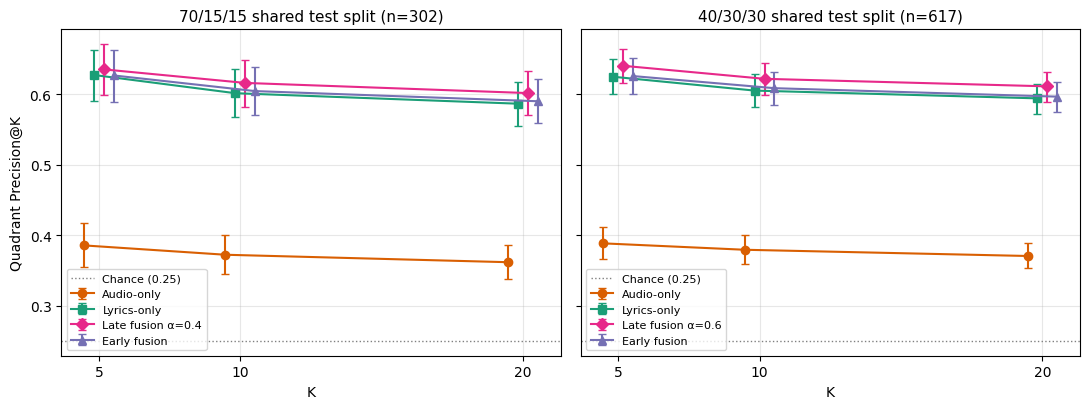

Saved: shared_split_precision_ci.png


In [8]:
STYLE = {'audio_only': ('#d95f02', 'o', 'Audio-only'), 'lyrics_only': ('#1b9e77', 's', 'Lyrics-only'),
         'early_fusion': ('#7570b3', '^', 'Early fusion')}
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2), sharey=True)
for ax, lbl in zip(axes, SCHEMES.values()):
    show_strats = ['audio_only', 'lyrics_only', best_alpha[lbl], 'early_fusion']
    for j, st in enumerate(show_strats):
        color, mk, name = STYLE.get(st, ('#e7298a', 'D', f"Late fusion α={st.split('_')[1]}"))
        s = summary[(summary.split == lbl) & (summary.strategy == st)].sort_values('k')
        x = np.array(K_LIST) + (j - 1.5) * 0.35
        ax.errorbar(x, s.precision, yerr=[s.precision - s.precision_ci_lo, s.precision_ci_hi - s.precision],
                    fmt=mk + '-', color=color, label=name, capsize=3, lw=1.5, ms=6)
    ax.axhline(0.25, color='gray', ls=':', lw=1, label='Chance (0.25)')
    n = summary[summary.split == lbl].n_queries.iloc[0]
    ax.set_title(f'{lbl} shared test split (n={n})', fontsize=11)
    ax.set_xticks(K_LIST); ax.set_xlabel('K'); ax.grid(alpha=0.3)
    ax.legend(fontsize=8, loc='lower left')
axes[0].set_ylabel('Quadrant Precision@K')
plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'shared_split_precision_ci.png'), dpi=200, bbox_inches='tight')
plt.show()
print('Saved: shared_split_precision_ci.png')